# 2.2b Diagnóstico de los modelos finales en `valid`

Los modelos finales de la 2.2 (YOLOv11n y YOLOv11s, 3 semillas cada uno, `resultados/configuracion_final.json`) se analizan en `valid` para identificar qué errores cometen. El test no se usa: se reserva para la evaluación final (2.3).

**Preguntas:**
1. **Tipo de error:** ¿fallan al detectar, al contar, al clasificar o al ajustar la caja?
2. **Dónde fallan:** ¿qué subtipos, lotes y escenas concentran los errores, y son sistemáticos?
3. **Confianza:** ¿distingue la confianza los aciertos de los errores?
4. **Objetos que no son maíz:** ¿se detectan como grano las impurezas de los lotes de `valid`?

**Criterios:**
- Las métricas de aplicación usan la configuración final de cada modelo: su umbral de conteo y NMS agnóstico a la clase.
- Un grano está **detectado** si una predicción lo cubre con IoU ≥ 0.5, y **acertado** si además la clase binaria es la correcta. `Healthy` e `Immature` forman la clase `Healthy`; los demás subtipos, `Defect`.
- Una predicción **sobrante** no tiene grano emparejado. Es **de fondo** si su IoU con todo grano anotado es menor que 0.1.
- Un error es **sistemático** si lo cometen las 6 corridas (los dos modelos con sus 3 semillas).

`valid` se usó para elegir `best.pt` y el umbral de conteo, así que sus métricas son optimistas. El diagnóstico describe el tipo de error, no estima el rendimiento. No entrena ni cambia los modelos.

In [1]:
import json
import os
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

os.environ['YOLO_VERBOSE'] = 'False'
import comun_oe2 as E

C = E.C
C.estilo()
RAIZ = Path.cwd()
SALIDA = RAIZ / 'salida' / '2.2b_diagnostico_valid'
CFG = E.configuracion('final')
ETIQUETA = {'yolo11n': 'YOLOv11n', 'yolo11s': 'YOLOv11s'}
CLASE = {0: 'Healthy', 1: 'Defect'}
VALID = sorted((E.FINAL / 'valid' / 'images').glob('*.jpg'))
CORRIDAS = [(m, s, p) for m, c in CFG.items() for s, p in zip(c['semillas'], c['pesos'])]
for m, c in CFG.items():
    print(f"{ETIQUETA[m]}: umbral de conteo {c['conf_conteo']}, semillas {c['semillas']}")
print(f'{len(VALID)} imágenes de valid')

YOLOv11n: umbral de conteo 0.4775, semillas [42, 7, 28]
YOLOv11s: umbral de conteo 0.2923, semillas [42, 7, 28]
115 imágenes de valid


## 1. Composición de `valid`

Las métricas dependen de qué escenas contiene cada conjunto: una bandeja con un solo subtipo es más fácil que una mezclada. Se compara `valid` con `train` y se describe cada lote de `valid`.

In [2]:
def composicion(split):
    filas = []
    for p in sorted((E.FINAL / split / 'images').glob('*.jpg')):
        _, cajas, cl, sub = E.cargar(p.stem, split)
        filas.append({'conjunto': split, 'stem': p.stem, 'lote': E.LOTE_CAPTURA[p.stem], 'granos': len(sub),
                      'varios subtipos': len(set(sub)) > 1, 'las dos clases': len(set(cl)) > 1,
                      'lado del grano (px)': np.median(np.sqrt((cajas[:, 2] - cajas[:, 0]) * (cajas[:, 3] - cajas[:, 1]))),
                      'subtipos': {E.NOMBRE[s] for s in sub}})
    return pd.DataFrame(filas)

comp = pd.concat([composicion(s) for s in ('train', 'valid')], ignore_index=True)
display(comp.groupby('conjunto', sort=False).agg(imágenes=('lote', 'size'), lotes=('lote', 'nunique'),
                                                 granos_por_imagen=('granos', 'median'),
                                                 con_varios_subtipos=('varios subtipos', 'mean'),
                                                 con_las_dos_clases=('las dos clases', 'mean'),
                                                 lado_del_grano=('lado del grano (px)', 'median')).round(2))
v = comp[comp.conjunto == 'valid']
display(v.groupby('lote').agg(imágenes=('granos', 'size'), granos_por_imagen=('granos', 'median'),
                              con_las_dos_clases=('las dos clases', 'mean'),
                              subtipos=('subtipos', lambda s: ', '.join(sorted(set().union(*s))))).round(2))

,imágenes,lotes,granos_por_imagen,con_varios_subtipos,con_las_dos_clases,lado_del_grano
conjunto,,,,,,
train,344,7,30.0,0.08,0.08,49.83
valid,115,7,30.0,0.21,0.21,60.90


,imágenes,granos_por_imagen,con_las_dos_clases,subtipos
lote,,,,
contador_DSC_000,10,31.0,0.00,Fungus
tiempo_000,6,90.5,1.00,"Broken, Damage, Fungus, Healthy, Immature, Shr..."
tiempo_001,2,97.5,1.00,"Broken, Damage, Fungus, Healthy, Immature, Shr..."
tiempo_003,8,51.0,1.00,"Damage, Fungus, Healthy, Immature, Weeveled"
tiempo_004,5,50.0,0.00,Immature
tiempo_007,60,30.0,0.00,"Fungus, Healthy, Shriveled"
tiempo_018,24,30.0,0.33,"Broken, Damage, Healthy, Immature, Shriveled, ..."


## 2. Tipo de error: detección, conteo y clasificación

Para cada modelo y semilla, con su umbral de conteo: estado de cada grano anotado, predicciones sobrantes y error de conteo por imagen.

In [3]:
granos, sobrantes, conteo = [], [], []
for modelo, semilla, pesos in CORRIDAS:
    pred = E.predecir(pesos, VALID, CFG[modelo]['conf_conteo'])
    g, s = E.diagnosticar(pred, 'valid')
    granos.append(g.assign(modelo=ETIQUETA[modelo], semilla=semilla))
    sobrantes.append(s.assign(modelo=ETIQUETA[modelo], semilla=semilla))
    n_gt = g.groupby('stem').size()
    conteo.append(pd.DataFrame({'stem': n_gt.index, 'lote': [E.LOTE_CAPTURA[x] for x in n_gt.index], 'granos': n_gt.values,
                                'predichos': [len(pred[x][0]) for x in n_gt.index]}).assign(modelo=ETIQUETA[modelo], semilla=semilla))
granos, sobrantes, conteo = (pd.concat(x, ignore_index=True) for x in (granos, sobrantes, conteo))
conteo['error'] = conteo['predichos'] - conteo['granos']

por_corrida = granos.groupby(['modelo', 'semilla']).estado.value_counts().unstack(fill_value=0)
por_corrida['sobrantes sobre un grano'] = sobrantes[sobrantes.tipo == 'sobre un grano'].groupby(['modelo', 'semilla']).size()
por_corrida['sobrantes de fondo'] = sobrantes[sobrantes.tipo == 'fondo'].groupby(['modelo', 'semilla']).size()
por_corrida = por_corrida.fillna(0).astype(int)
por_corrida['MAE de conteo'] = conteo.groupby(['modelo', 'semilla']).error.apply(lambda e: e.abs().mean()).round(3)
por_corrida['error con signo'] = conteo.groupby(['modelo', 'semilla']).error.mean().round(3)
print(f"{granos.groupby(['modelo', 'semilla']).size().iloc[0]} granos anotados en {len(VALID)} imágenes")
display(por_corrida)
display((granos.groupby('modelo').estado.value_counts(normalize=True).unstack() * 100).round(2).rename_axis(columns='% de los granos'))

4242 granos anotados en 115 imágenes


estado            acierto  clase cambiada  no detectado  \
modelo   semilla                                          
YOLOv11n 7           3551             639            52   
         28          3752             468            22   
         42          3711             499            32   
YOLOv11s 7           3638             577            27   
         28          3734             501             7   
         42          3472             754            16   

estado            sobrantes sobre un grano  sobrantes de fondo  MAE de conteo  \
modelo   semilla                                                                
YOLOv11n 7                              48                  41          0.513   
         28                             29                  34          0.513   
         42                             27                  35          0.348   
YOLOv11s 7                              35                  33          0.635   
         28                             38                  52          0.739   
         42                             50                  47          0.722   

estado            error con signo  
modelo   semilla                   
YOLOv11n 7                  0.322  
         28                 0.357  
         42                 0.261  
YOLOv11s 7                  0.357  
         28                 0.722  
         42                 0.704

% de los granos,acierto,clase cambiada,no detectado
modelo,,,
YOLOv11n,86.55,12.62,0.83
YOLOv11s,85.21,14.40,0.39


### 2.1. Clasificación por subtipo

Fracción de granos de cada subtipo acertados, con la clase binaria cambiada o no detectados (media de las 3 semillas).

estado     acierto          clase cambiada          no detectado           \
modelo    YOLOv11n YOLOv11s       YOLOv11n YOLOv11s     YOLOv11n YOLOv11s   
subtipo                                                                     
Broken       0.841    0.866          0.117    0.117        0.042    0.017   
Damage       0.799    0.857          0.195    0.143        0.006    0.000   
Fungus       0.978    0.983          0.021    0.017        0.000    0.000   
Shriveled    0.946    0.939          0.036    0.049        0.018    0.012   
Weeveled     0.845    0.897          0.154    0.103        0.001    0.000   
Healthy      0.844    0.808          0.154    0.192        0.003    0.000   
Immature     0.705    0.636          0.275    0.352        0.020    0.011   

estado    granos  
modelo            
subtipo           
Broken       176  
Damage       214  
Fungus       837  
Shriveled    625  
Weeveled     358  
Healthy     1491  
Immature     541

acierto por semilla     7      28     42
modelo   subtipo                        
YOLOv11n Broken      0.932  0.756  0.835
         Damage      0.930  0.673  0.794
         Fungus      0.998  0.973  0.965
         Shriveled   0.966  0.931  0.939
         Weeveled    0.961  0.827  0.749
         Healthy     0.785  0.881  0.865
         Immature    0.433  0.867  0.817
YOLOv11s Broken      0.830  0.869  0.898
         Damage      0.883  0.766  0.921
         Fungus      0.989  0.965  0.995
         Shriveled   0.939  0.930  0.947
         Weeveled    0.933  0.768  0.989
         Healthy     0.816  0.860  0.746
         Immature    0.623  0.871  0.416

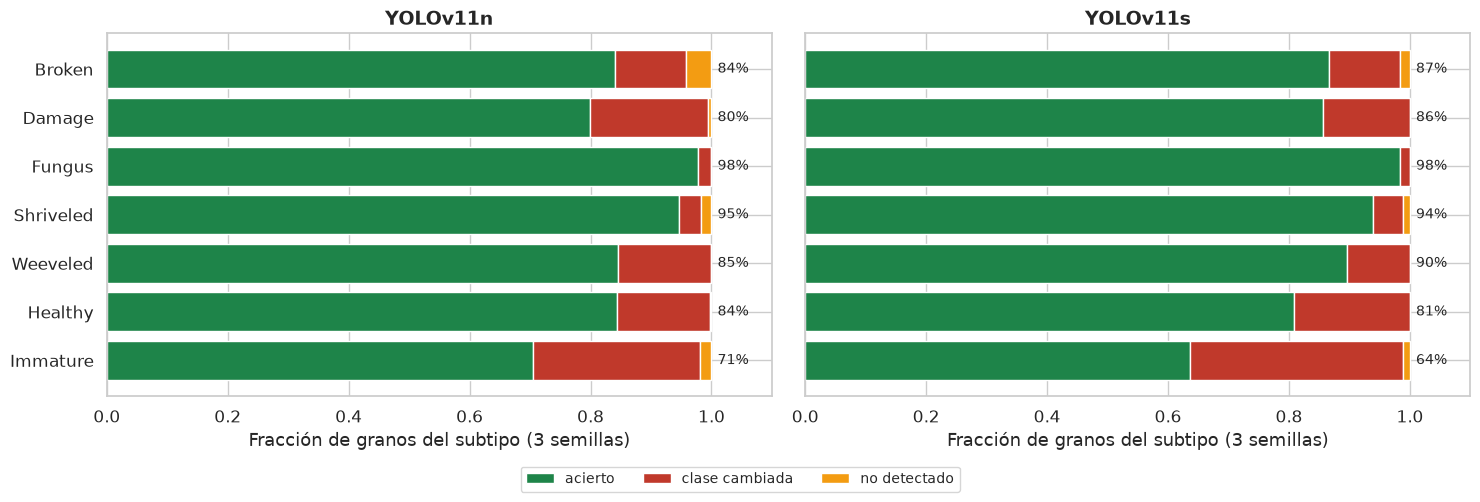

In [4]:
ORDEN = ['Broken', 'Damage', 'Fungus', 'Shriveled', 'Weeveled', 'Healthy', 'Immature']
ESTADOS = {'acierto': E.OK, 'clase cambiada': E.MAL, 'no detectado': '#F39C12'}
frac = (granos.groupby(['modelo', 'subtipo']).estado.value_counts(normalize=True).unstack(fill_value=0)
        .reindex(columns=list(ESTADOS), fill_value=0))
n_sub = granos[(granos.modelo == 'YOLOv11n') & (granos.semilla == CFG['yolo11n']['semillas'][0])].groupby('subtipo').size()
display(frac.round(3).unstack('modelo').reindex(ORDEN).assign(granos=n_sub))
por_semilla = granos.groupby(['modelo', 'subtipo', 'semilla']).estado.apply(lambda e: (e == 'acierto').mean()).unstack('semilla')
display(por_semilla.reindex(ORDEN, level=1).round(3).rename_axis(columns='acierto por semilla'))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, modelo in zip(axes, ETIQUETA.values()):
    f = frac.loc[modelo].reindex(ORDEN)
    izq = np.zeros(len(f))
    for estado, color in ESTADOS.items():
        ax.barh(ORDEN[::-1], f[estado].values[::-1], left=izq[::-1], color=color, label=estado)
        izq += f[estado].values
    for i, s in enumerate(ORDEN[::-1]):
        ax.text(1.01, i, f"{f.loc[s, 'acierto']:.0%}", va='center', fontsize=10)
    ax.set_xlim(0, 1.1); ax.set_title(modelo); ax.set_xlabel('Fracción de granos del subtipo (3 semillas)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.06), fontsize=10)
C.guardar(SALIDA, 'estado_por_subtipo.png')

### 2.2. Ajuste de las cajas

El mAP50-95 promedia la precisión con IoU de 0.50 a 0.95, así que también mide cuánto se ajusta cada caja al grano. Se analiza el IoU entre cada grano detectado y su predicción.

media          IoU ≥ 0.75          IoU ≥ 0.90         
modelo    YOLOv11n YOLOv11s   YOLOv11n YOLOv11s   YOLOv11n YOLOv11s
subtipo                                                            
Broken       0.884    0.884      0.945    0.950      0.484    0.491
Damage       0.885    0.884      0.947    0.947      0.506    0.484
Fungus       0.897    0.902      0.964    0.966      0.597    0.653
Shriveled    0.849    0.851      0.873    0.879      0.329    0.331
Weeveled     0.849    0.848      0.793    0.795      0.445    0.418
Healthy      0.876    0.877      0.949    0.953      0.406    0.398
Immature     0.833    0.836      0.856    0.859      0.196    0.215

,media,mediana,IoU ≥ 0.75,IoU ≥ 0.90
modelo,,,,
YOLOv11n,0.869,0.888,0.916,0.418
YOLOv11s,0.871,0.889,0.919,0.425


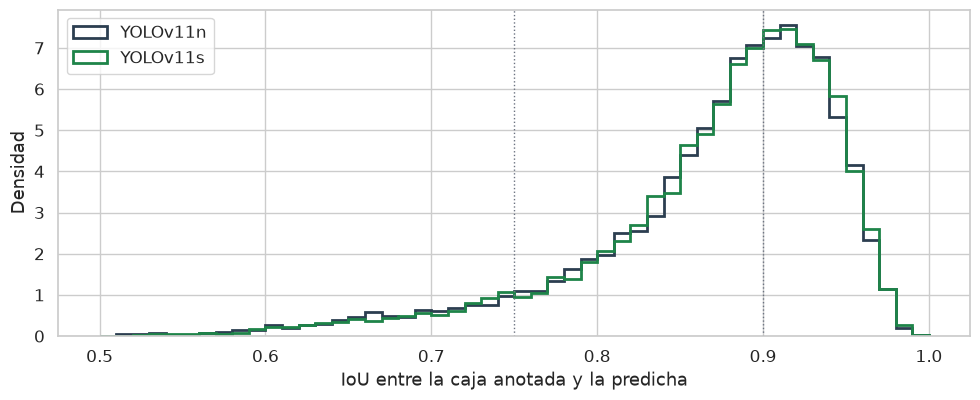

In [5]:
det = granos[granos.estado != 'no detectado']
ajuste = det.groupby(['modelo', 'subtipo']).iou.agg(media='mean', **{'IoU ≥ 0.75': lambda x: (x >= 0.75).mean(),
                                                                   'IoU ≥ 0.90': lambda x: (x >= 0.90).mean()})
display(ajuste.unstack('modelo').reindex(ORDEN).round(3))
display(det.groupby('modelo').iou.agg(media='mean', mediana='median', **{'IoU ≥ 0.75': lambda x: (x >= 0.75).mean(),
                                                                         'IoU ≥ 0.90': lambda x: (x >= 0.90).mean()}).round(3))

fig, ax = plt.subplots(figsize=(10, 4.2))
for modelo, color in zip(ETIQUETA.values(), (E.NEUTRO, E.OK)):
    ax.hist(det[det.modelo == modelo].iou, bins=np.linspace(0.5, 1, 51), histtype='step', lw=2, density=True, color=color, label=modelo)
for u in (0.75, 0.9):
    ax.axvline(u, color=E.GRIS, ls=':', lw=1)
ax.set_xlabel('IoU entre la caja anotada y la predicha'); ax.set_ylabel('Densidad'); ax.legend()
C.guardar(SALIDA, 'ajuste_cajas.png')

### 2.3. Confianza de aciertos y errores

Si los errores de clase tuvieran una confianza claramente menor que los aciertos, podrían señalarse para revisión manual.

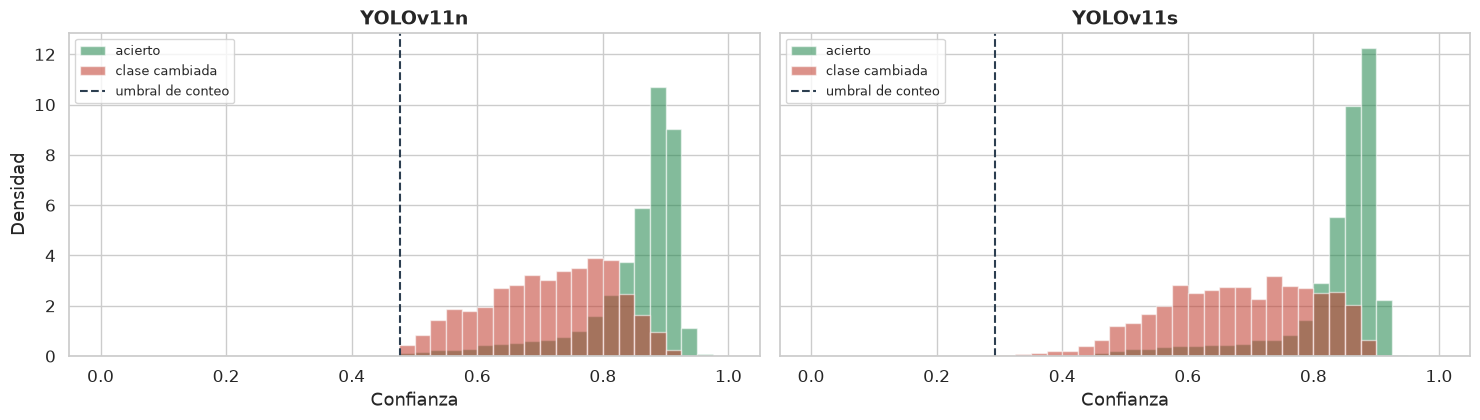

estado,acierto,clase cambiada
modelo,,
YOLOv11n,0.878,0.725
YOLOv11s,0.863,0.688


,modelo,confianza menor que,errores de clase señalados,aciertos señalados
0,YOLOv11n,0.6,0.159,0.027
1,YOLOv11n,0.7,0.427,0.077
2,YOLOv11s,0.6,0.268,0.045
3,YOLOv11s,0.7,0.533,0.089


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), sharey=True)
bins = np.linspace(0, 1, 41)
filas = []
for ax, (modelo, c) in zip(axes, CFG.items()):
    d = det[det.modelo == ETIQUETA[modelo]]
    for estado, color in (('acierto', E.OK), ('clase cambiada', E.MAL)):
        ax.hist(d[d.estado == estado].conf, bins=bins, density=True, alpha=0.55, color=color, label=estado)
    ax.axvline(c['conf_conteo'], color=E.NEUTRO, ls='--', lw=1.5, label='umbral de conteo')
    ax.set_title(ETIQUETA[modelo]); ax.set_xlabel('Confianza'); ax.legend(fontsize=9)
    for u in (0.6, 0.7):
        filas.append({'modelo': ETIQUETA[modelo], 'confianza menor que': u,
                      'errores de clase señalados': (d[d.estado == 'clase cambiada'].conf < u).mean(),
                      'aciertos señalados': (d[d.estado == 'acierto'].conf < u).mean()})
axes[0].set_ylabel('Densidad')
C.guardar(SALIDA, 'confianza_errores.png')
display(det.groupby(['modelo', 'estado']).conf.median().unstack().round(3))
display(pd.DataFrame(filas).round(3))

## 3. Dónde fallan: lotes, escenas y errores sistemáticos

In [7]:
por_lote = (granos.groupby(['lote', 'modelo']).estado.value_counts(normalize=True).unstack(fill_value=0)
            .reindex(columns=list(ESTADOS), fill_value=0).round(3))
por_lote['MAE de conteo'] = conteo.groupby(['lote', 'modelo']).error.apply(lambda e: e.abs().mean()).round(3)
por_lote['granos (por corrida)'] = granos.groupby(['lote', 'modelo']).size() // len(CFG['yolo11n']['semillas'])
display(por_lote)

# Escenas: imágenes con una sola clase binaria frente a imágenes con granos sanos y defectuosos
mezcla = comp[comp.conjunto == 'valid'].set_index('stem')['las dos clases']
ESCENA = {True: 'las dos clases', False: 'una sola clase'}
granos['escena'] = granos.stem.map(mezcla).map(ESCENA)
print('Imágenes de valid por escena:', mezcla.map(ESCENA).value_counts().to_dict())
display(granos.groupby(['modelo', 'escena', 'clase']).estado.apply(lambda e: (e == 'acierto').mean()).unstack('clase')
        .rename(columns=CLASE).round(3).rename_axis(columns='acierto por clase'))

errores = granos[granos.estado != 'acierto']
veces = errores.groupby(['stem', 'grano']).size()
sistematicos = (errores.set_index(['stem', 'grano']).loc[veces[veces == len(CORRIDAS)].index]
                .reset_index().drop_duplicates(['stem', 'grano']))
total = granos.groupby(['modelo', 'semilla']).size().iloc[0]
print(f'Granos con algún error en alguna corrida: {len(veces)} de {total}; sistemáticos ({len(CORRIDAS)} de {len(CORRIDAS)}): {len(sistematicos)}')
display(pd.crosstab([sistematicos['lote'], sistematicos['subtipo']], sistematicos['estado']).rename_axis(None, axis=1))

estado                     acierto  clase cambiada  no detectado  \
lote             modelo                                            
contador_DSC_000 YOLOv11n    1.000           0.000         0.000   
                 YOLOv11s    0.998           0.002         0.000   
tiempo_000       YOLOv11n    0.608           0.368         0.024   
                 YOLOv11s    0.572           0.425         0.003   
tiempo_001       YOLOv11n    0.624           0.294         0.082   
                 YOLOv11s    0.496           0.446         0.058   
tiempo_003       YOLOv11n    0.646           0.353         0.001   
                 YOLOv11s    0.681           0.319         0.000   
tiempo_004       YOLOv11n    0.625           0.368         0.007   
                 YOLOv11s    0.523           0.473         0.004   
tiempo_007       YOLOv11n    0.998           0.000         0.002   
                 YOLOv11s    0.998           0.001         0.001   
tiempo_018       YOLOv11n    0.945           0.054         0.001   
                 YOLOv11s    0.946           0.054         0.000   

estado                     MAE de conteo  granos (por corrida)  
lote             modelo                                         
contador_DSC_000 YOLOv11n          0.000                   311  
                 YOLOv11s          0.000                   311  
tiempo_000       YOLOv11n          6.278                   549  
                 YOLOv11s         10.333                   549  
tiempo_001       YOLOv11n          2.833                   195  
                 YOLOv11s          5.667                   195  
tiempo_003       YOLOv11n          0.042                   408  
                 YOLOv11s          0.000                   408  
tiempo_004       YOLOv11n          0.333                   250  
                 YOLOv11s          0.067                   250  
tiempo_007       YOLOv11n          0.033                  1801  
                 YOLOv11s          0.017                  1801  
tiempo_018       YOLOv11n          0.222                   728  
                 YOLOv11s          0.236                   728

Imágenes de valid por escena: {'una sola clase': 91, 'las dos clases': 24}


acierto por clase        Healthy  Defect
modelo   escena                         
YOLOv11n las dos clases    0.536   0.770
         una sola clase    0.932   0.997
YOLOv11s las dos clases    0.436   0.817
         una sola clase    0.913   0.997

Granos con algún error en alguna corrida: 1252 de 4242; sistemáticos (6 de 6): 81


clase cambiada  no detectado
lote       subtipo                                
tiempo_000 Damage                  1             0
           Healthy                 4             0
           Immature                3             0
           Shriveled               4             0
tiempo_001 Broken                  1             1
           Healthy                 1             0
           Shriveled               3             4
tiempo_003 Healthy                40             0
           Immature                2             0
tiempo_004 Immature                4             0
tiempo_007 Shriveled               0             2
tiempo_018 Healthy                10             0
           Immature                1             0

### 3.1. Galería de errores sistemáticos

Recortes de granos que las 6 corridas clasifican mal, hasta 12 por subtipo. Caja: la anotación; título: subtipo anotado → clase predicha por la corrida representativa de YOLOv11s (la de mAP50-95 mediano en `valid`).

Semilla de las figuras: {'YOLOv11n': 7, 'YOLOv11s': 7}


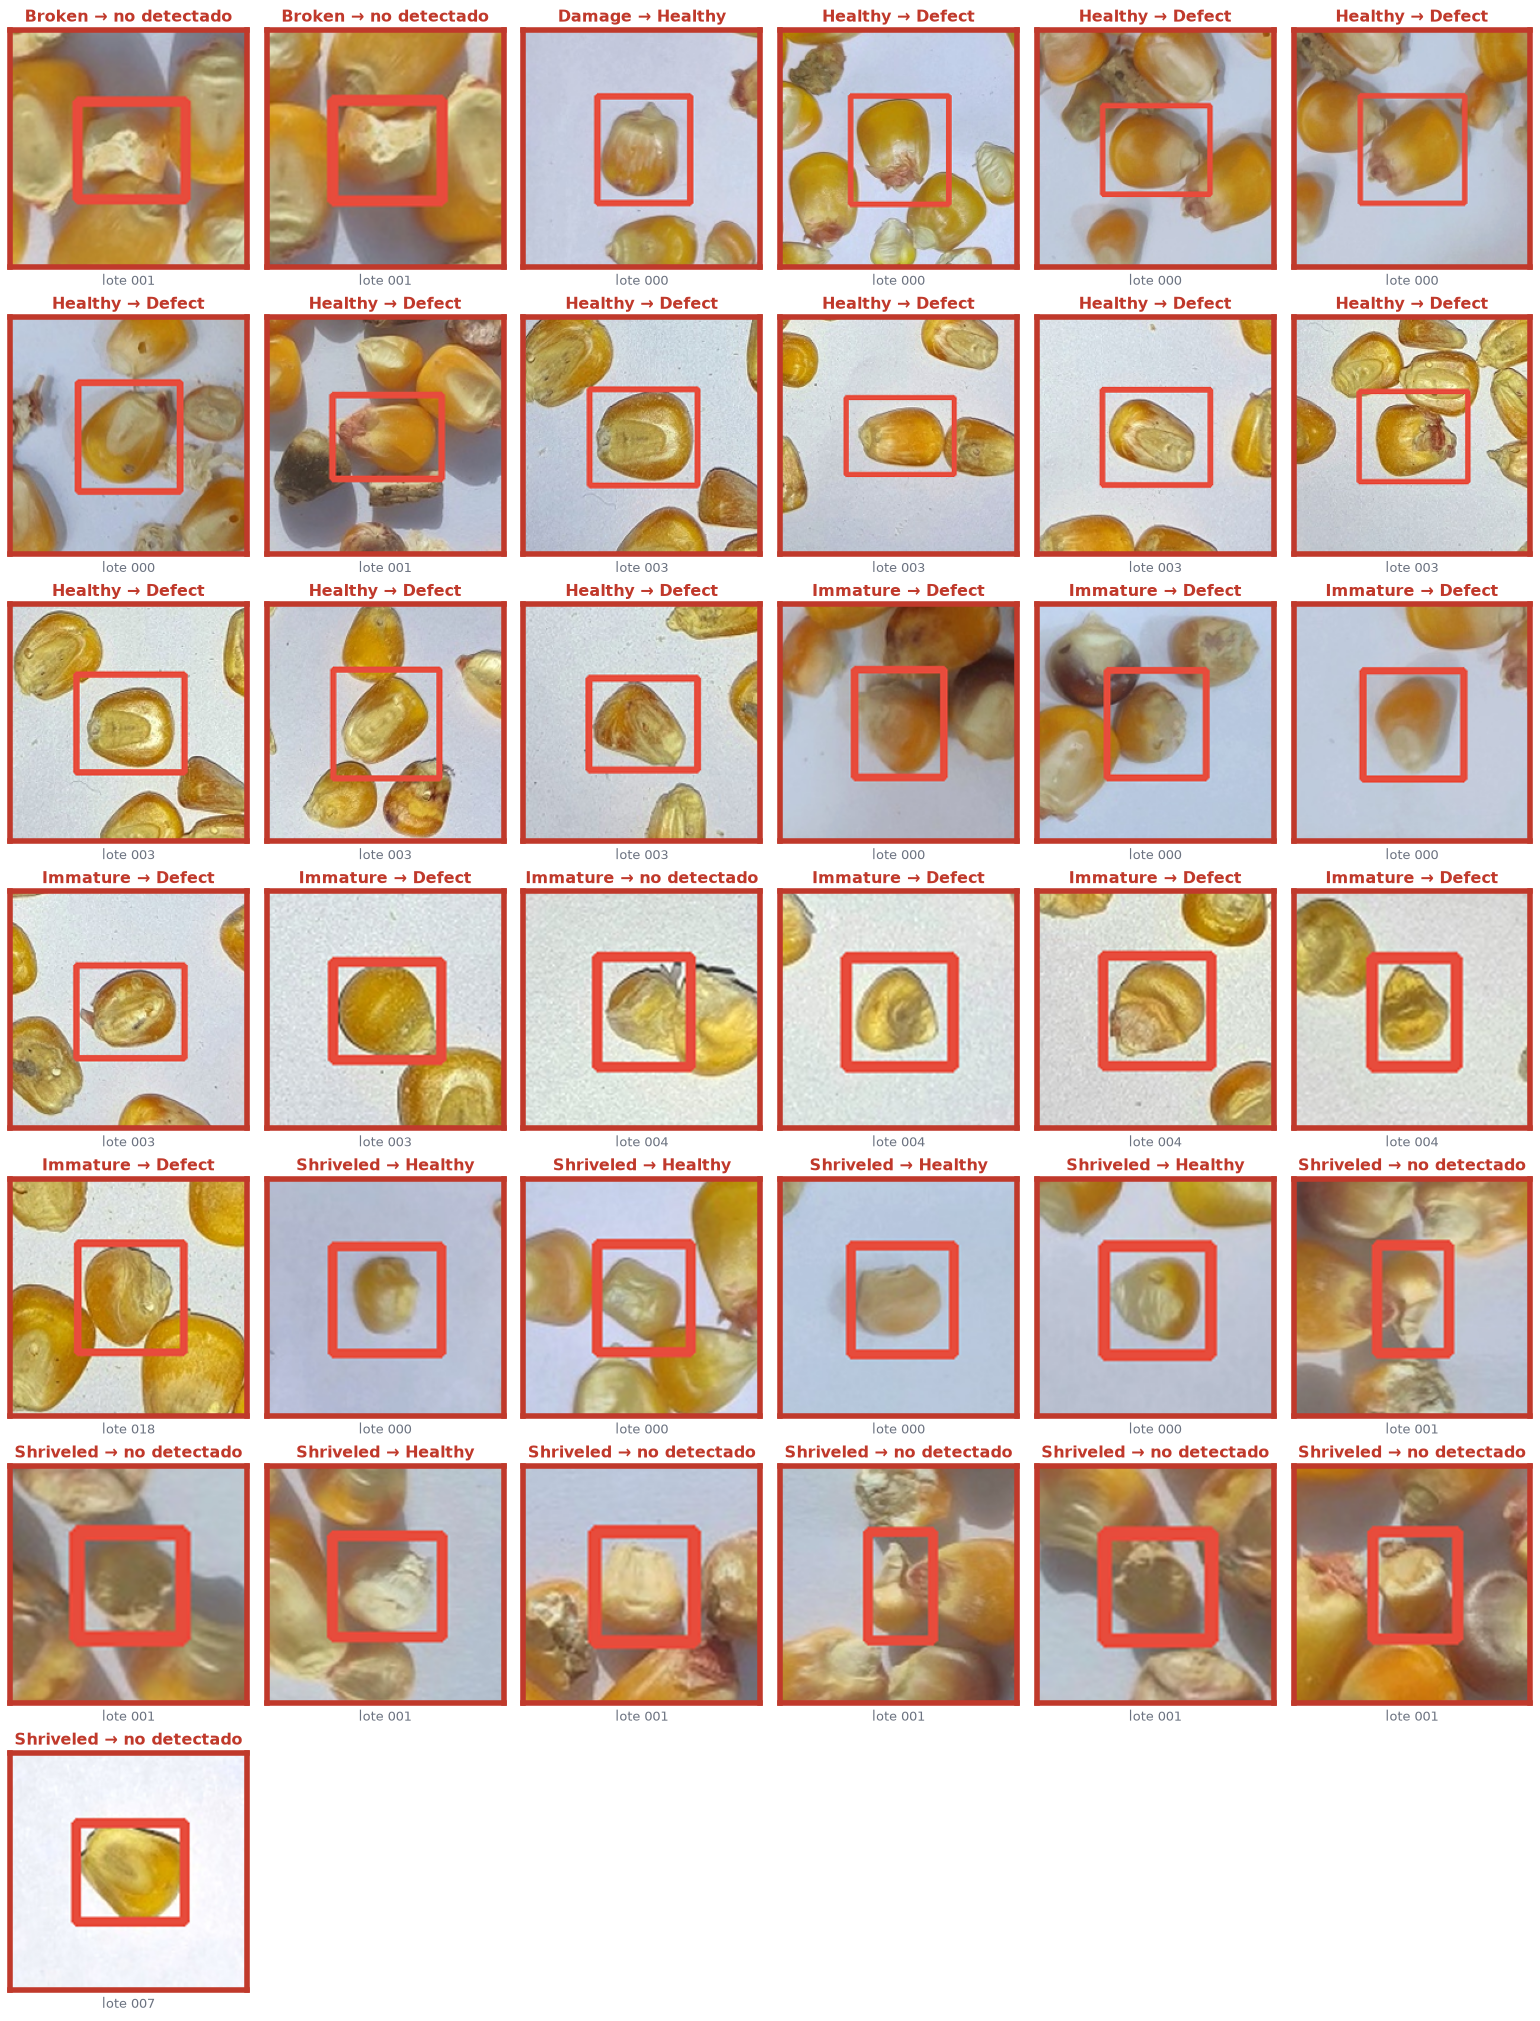

In [8]:
def galeria(filas, titulo_de, archivo, columnas=6, lado=200, split='valid'):
    filas = list(filas)
    n = len(filas); r = max(int(np.ceil(n / columnas)), 1)
    fig, axes = plt.subplots(r, columnas, figsize=(2.6 * columnas, 2.9 * r), squeeze=False)
    for ax in np.ravel(axes)[n:]:
        ax.axis('off')
    cache = {}
    for ax, f in zip(np.ravel(axes), filas):
        if f['stem'] not in cache:
            cache[f['stem']] = (cv2.cvtColor(cv2.imread(str(f['ruta'])), cv2.COLOR_BGR2RGB) if 'ruta' in f
                                else E.cargar(f['stem'], split)[0])
        b = np.asarray(f['caja'], float); L = int(max(b[2] - b[0], b[3] - b[1]) * 2.2)
        rec, _ = E.recorte(E.dibujar(cache[f['stem']], [b], E.CAJA_MAL, 3), ((b[0] + b[2]) / 2, (b[1] + b[3]) / 2), L, lado)
        E.mostrar(ax, rec, *titulo_de(f), estado='mal')
    C.guardar(SALIDA, archivo)

# Corrida representativa de cada modelo para las figuras: la de mAP50-95 mediano en valid entre sus 3 semillas,
# elegida sin mirar estas imágenes (las tablas usan las 3 semillas)
_final = E.leer_registro().query("fase == 'final'")
SEMILLA_FIG = {m: int(g.sort_values('mAP50_95')['semilla'].iloc[len(g) // 2]) for m, g in _final.groupby('modelo')}
ETIQ_INV = {v: k for k, v in ETIQUETA.items()}
print('Semilla de las figuras:', {ETIQUETA[m]: s for m, s in SEMILLA_FIG.items()})
S0 = SEMILLA_FIG['yolo11s']
ref = granos[(granos.modelo == 'YOLOv11s') & (granos.semilla == S0)].set_index(['stem', 'grano'])['clase_pred']
muestra = (sistematicos.assign(pred=[ref.get((s, g)) for s, g in zip(sistematicos.stem, sistematicos.grano)])
           .sort_values(['subtipo', 'lote']).groupby('subtipo', group_keys=False).head(12))
if len(muestra):
    galeria(muestra.to_dict('records'),
            lambda f: (f"{f['subtipo']} → {CLASE[int(f['pred'])] if pd.notna(f['pred']) else 'no detectado'}",
                       f"lote {f['lote'].split('_')[-1]}"),
            'errores_sistematicos.png')

### 3.2. Imagen con más errores sistemáticos

Con las predicciones de la corrida representativa de YOLOv11s (la de mAP50-95 mediano en `valid`). Verde: acierto; rojo: clase cambiada; naranja: no detectado; azul: predicción sobrante.

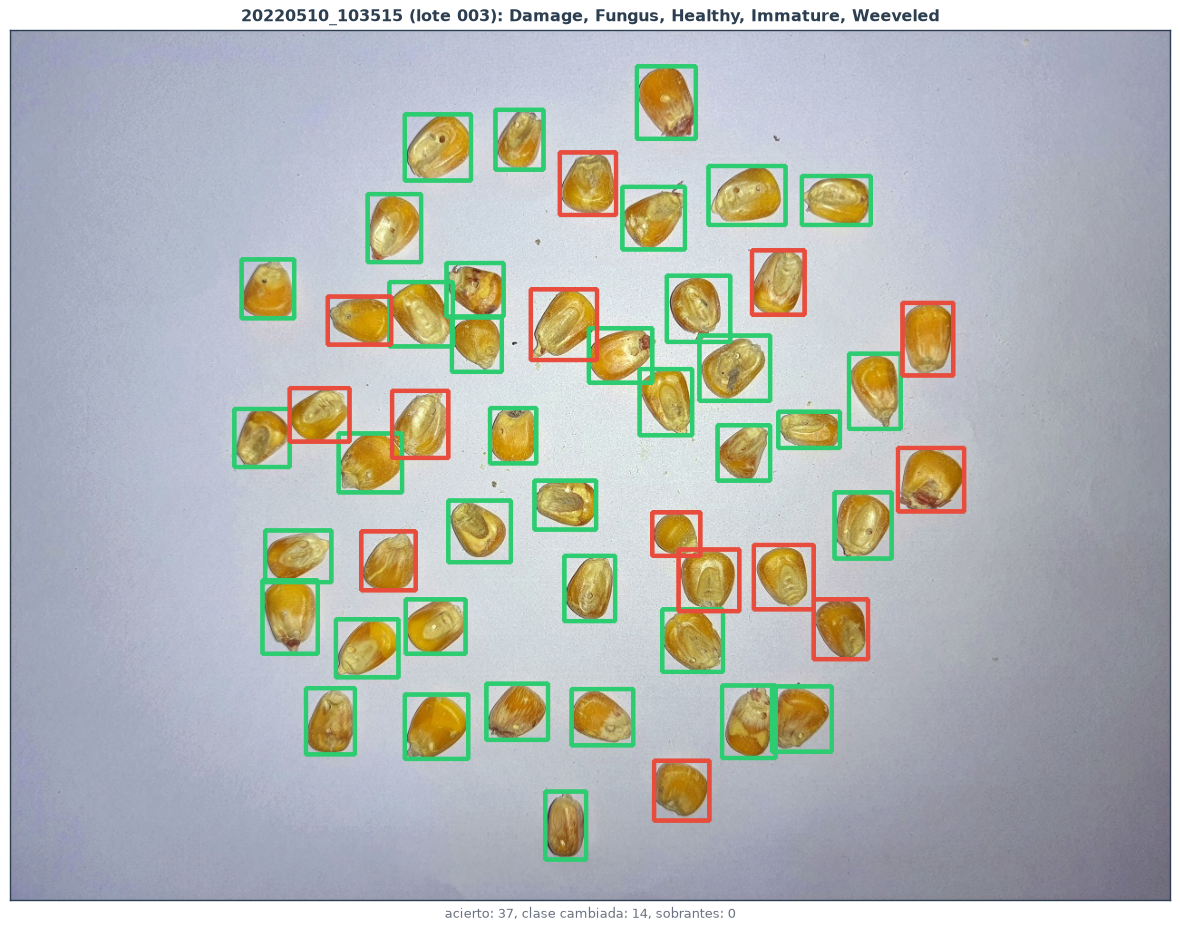

In [9]:
peor = sistematicos.stem.value_counts().index[0]
img = E.cargar(peor, 'valid')[0]
g = granos[(granos.stem == peor) & (granos.modelo == 'YOLOv11s') & (granos.semilla == S0)]
s = sobrantes[(sobrantes.stem == peor) & (sobrantes.modelo == 'YOLOv11s') & (sobrantes.semilla == S0)]
vista = img.copy()
for estado, color in (('acierto', E.CAJA_OK), ('clase cambiada', E.CAJA_MAL), ('no detectado', (243, 156, 18))):
    if (g.estado == estado).any():
        vista = E.dibujar(vista, np.stack(g[g.estado == estado].caja.values), color, 3)
if len(s):
    vista = E.dibujar(vista, np.stack(s.caja.values), E.CAJA_B, 3)
fig, ax = plt.subplots(figsize=(12, 9.5))
E.mostrar(ax, vista, f"{peor[:15]} (lote {E.LOTE_CAPTURA[peor].split('_')[-1]}): "
          + ', '.join(sorted({E.NOMBRE[x] for x in E.cargar(peor, 'valid')[3]})),
          ', '.join(f'{k}: {v}' for k, v in g.estado.value_counts().items()) + f', sobrantes: {len(s)}')
C.guardar(SALIDA, 'peor_imagen.png')

## 4. Objetos que no son maíz

Las 18 imágenes de impurezas de los lotes de `valid` y las 3 hojas de medición (`datos/fondos`), con el mismo preprocesamiento que el dataset. No intervienen en el entrenamiento. Toda predicción en ellas es un falso positivo. Se mide cuántas impurezas se detectan como grano (IoU ≥ 0.5), con qué clase y con qué confianza, frente a los granos de `valid`.

In [10]:
info = E.fondos_info()
MEDICION = [E.FONDOS / 'images' / f'{n}.jpg' for n in info['particiones']['valid']['medicion']]

def cajas_impurezas(p):
    H, W = cv2.imread(str(p)).shape[:2]
    c, _ = C.leer_yolo(E.FONDOS / 'impurezas' / f'{p.stem}.txt')
    c = np.array(c, float).reshape(-1, 4)
    return np.stack([(c[:, 0] - c[:, 2] / 2) * W, (c[:, 1] - c[:, 3] / 2) * H, (c[:, 0] + c[:, 2] / 2) * W, (c[:, 1] + c[:, 3] / 2) * H], 1)

ANOT = {p.stem: cajas_impurezas(p) for p in MEDICION}
TIPO = {p.stem: info['imagenes'][p.stem]['tipo'] for p in MEDICION}
objetos, detecciones = [], []
for modelo, semilla, pesos in CORRIDAS:
    pred = E.predecir(pesos, MEDICION, CFG[modelo]['conf_conteo'])
    for stem, (pb, pc, pf) in pred.items():
        gt = ANOT[stem]
        pares = E.emparejar(gt, pb)[0] if len(gt) else {}
        for o in range(len(gt)):
            q = pares.get(o)
            objetos.append({'modelo': ETIQUETA[modelo], 'semilla': semilla, 'stem': stem, 'tipo': TIPO[stem],
                            'detectado': q is not None, 'clase_pred': None if q is None else CLASE[int(pc[q])],
                            'conf': None if q is None else float(pf[q]), 'caja': gt[o]})
        detecciones.append({'modelo': ETIQUETA[modelo], 'semilla': semilla, 'stem': stem, 'tipo': TIPO[stem],
                            'objetos': len(gt), 'detecciones': len(pb), 'confianzas': list(pf)})
objetos, detecciones = pd.DataFrame(objetos), pd.DataFrame(detecciones)
t = detecciones.groupby(['modelo', 'tipo']).agg(imágenes=('stem', 'nunique'), objetos_por_imagen=('objetos', 'mean'),
                                                 detecciones_por_imagen=('detecciones', 'mean'))
t['impurezas detectadas como grano'] = objetos.groupby(['modelo', 'tipo']).detectado.mean()
display(t.round(3))
display(detecciones.groupby(['modelo', 'semilla']).detecciones.sum().unstack('semilla').rename_axis(columns='detecciones en las 21 imágenes'))
conf_fp = detecciones.explode('confianzas').dropna(subset=['confianzas'])
display(conf_fp.groupby('modelo').confianzas.agg(['size', 'median', 'max']).rename(columns={'size': 'falsos positivos', 'median': 'confianza mediana', 'max': 'confianza máxima'}))
display(det.groupby('modelo').conf.median().rename('confianza mediana de los granos detectados').round(3))

imágenes  objetos_por_imagen  detecciones_por_imagen  \
modelo   tipo                                                              
YOLOv11n Inorganic         4              30.750                   0.000   
         Organic          14              30.429                   0.238   
         hoja              3               0.000                   0.000   
YOLOv11s Inorganic         4              30.750                   0.000   
         Organic          14              30.429                   1.857   
         hoja              3               0.000                   0.000   

                    impurezas detectadas como grano  
modelo   tipo                                        
YOLOv11n Inorganic                            0.000  
         Organic                              0.008  
         hoja                                   NaN  
YOLOv11s Inorganic                            0.000  
         Organic                              0.059  
         hoja                                   NaN

detecciones en las 21 imágenes,7,28,42
modelo,,,
YOLOv11n,1,1,8
YOLOv11s,4,1,73


,falsos positivos,confianza mediana,confianza máxima
modelo,,,
YOLOv11n,10,0.658457,0.771532
YOLOv11s,78,0.659525,0.850276


modelo
YOLOv11n    0.869
YOLOv11s    0.854
Name: confianza mediana de los granos detectados, dtype: float64

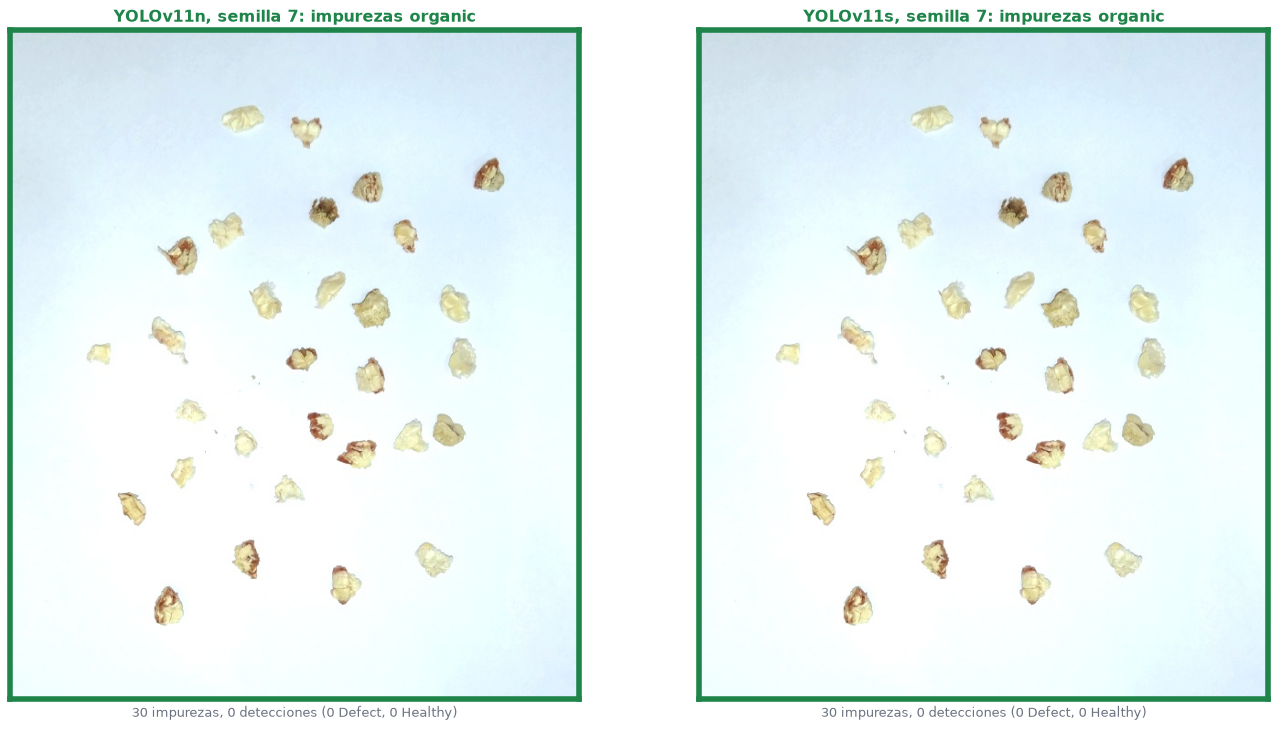

In [11]:
# La imagen de impurezas con más detecciones (sumando las 6 corridas), con la corrida representativa de cada modelo
peor_imp = detecciones.groupby('stem').detecciones.sum().idxmax()
ruta = next(p for p in MEDICION if p.stem == peor_imp)
img = cv2.cvtColor(cv2.imread(str(ruta)), cv2.COLOR_BGR2RGB)
x1, y1 = (ANOT[peor_imp][:, :2].min(0) - 80).clip(0).astype(int)
x2, y2 = (ANOT[peor_imp][:, 2:].max(0) + 80).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
for ax, (modelo, c) in zip(axes, CFG.items()):
    s = SEMILLA_FIG[modelo]
    pb, pc, pf = E.predecir(c['pesos'][c['semillas'].index(s)], [ruta], c['conf_conteo'])[peor_imp]
    vista = E.dibujar(E.dibujar(img, pb[pc == 0], E.CAJA_OK, 4), pb[pc == 1], E.CAJA_MAL, 4)[y1:y2, x1:x2]
    E.mostrar(ax, vista, f"{ETIQUETA[modelo]}, semilla {s}: impurezas {TIPO[peor_imp].lower()}",
              f"{len(ANOT[peor_imp])} impurezas, {len(pb)} detecciones ({(pc == 1).sum()} Defect, {(pc == 0).sum()} Healthy)",
              estado='mal' if len(pb) else 'ok')
C.guardar(SALIDA, 'impurezas_imagen.png')